# Proyecto Housing: EDA

## Entendimiento Contextual

Los datos corresponden a casas ubicadas en un distrito de California y algunas estadísticas resumidas basadas en el censo de 1990. Las columnas son las siguientes:

- longitude: Medida de qué tan al oeste se encuentra una casa; un valor mayor indica más al oeste.

- latitude: Medida de qué tan al norte se encuentra una casa; un valor mayor indica más al norte.

- housing_median_age: Edad mediana de las casas en un bloque; un número menor indica un edificio más nuevo.

- total_rooms: Número total de habitaciones en un bloque.

- total_bedrooms: Número total de dormitorios en un bloque.

- population: Número total de personas que residen en un bloque.

- households: Número total de hogares (grupo de personas que residen en una unidad habitacional) en un bloque.

- median_income: Ingreso mediano de los hogares en un bloque (medido en decenas de miles de dólares estadounidenses).

- median_house_value: Valor mediano de las casas en un bloque (medido en dólares estadounidenses).

- ocean_proximity: Ubicación de la casa respecto al océano/mar.

## Metadata

In [ ]:
# Metadatos del proyecto
from datetime import datetime
AUTOR = "Mgtr. Ronald Osorio"
FECHA_MODIFICACION = datetime.now().strftime("%d/%m/%Y %H:%M:%S")

print(f"Autor: {AUTOR}")
print(f"Última modificación: {FECHA_MODIFICACION}\n" + "-"*40)

Autor: Mgtr. Ronald Osorio
Última modificación: 18/10/2026 14:42:27
----------------------------------------


## Entorno

In [2]:
# General
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Módulos locales
import sys
sys.path.append('C:/Users/games/OneDrive/DS/Clases/Utils')
from eda_regression import *
from descriptive_analysis import *

## Dataset

In [3]:
import os

ruta = os.getcwd()
ruta_csv = os.path.join(ruta, 'housing_limpio.csv')
df = pd.read_csv(ruta_csv)
df.head()


,longitude,latitude,house_age,rooms,bedrooms,population,households,income,price,ocean_dist
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,near bay
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,near bay
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,near bay
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,near bay
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,near bay


## Renombrado de Columnas

In [ ]:
# Definir mapeo de renombre para las variables
rename_dict = {
    "housing_median_age": "house_age",
    "total_rooms": "rooms",
    "total_bedrooms": "bedrooms",
    "households": "households",
    "median_income": "income",
    "median_house_value": "price",
    "ocean_proximity": "ocean_dist"
}

# Validar presencia de columnas antes de ejecutar
print('=== === ORIGINAL === COLUMNS ===')
print(df.columns.tolist())
print('\n=== NOT FOUND ===')
missing = [col for col in rename_dict if col not in df.columns]
df = df.rename(columns=rename_dict)
print('\n=== FIXED COLUMNAS ===')
print(df.columns.tolist())

=== === ORIGINAL === COLUMNS ===
['longitude', 'latitude', 'house_age', 'rooms', 'bedrooms', 'population', 'households', 'income', 'price', 'ocean_dist']

=== NOT FOUND ===

=== FIXED COLUMNAS ===
['longitude', 'latitude', 'house_age', 'rooms', 'bedrooms', 'population', 'households', 'income', 'price', 'ocean_dist']


## Distribución de Columnas

In [5]:
target = 'price'
df_num = df[['longitude', 'latitude', 'house_age', 'rooms', 'bedrooms', 'population', 'households', 'income']]
df_bina = df[[ ]]
df_tiem = df[[]]
df_cat = df[['ocean_dist']]


# Configuración. Columnas para transformar
columnas_cat = ['ocean_dist']

# Transformando
df[columnas_cat] = df[columnas_cat].astype('category')
df_cat[columnas_cat] = df_cat[columnas_cat].astype('category')

## Hallazgos clave
| Objetivos | Descripción | Columnas | Listo |
| :--- | :--- | :--- | :--- |
| 1. Datos faltantes y patrones  |Sí | bedrooms|P |
| 2. Duplicados | Ninguno, pero verificar después de split| | ✓  | 
| 3. Valores atípicos |Sí	|rooms, bedrooms, population, households, income, price |P |
| 4. Transformación del objetivo  |Sí |  |P|
| 5. Poder predictivo de las variables | Conservar las menos potentes. Ninguna con poder 0|population | ✓|
| 6. Escalado de datos |Sí |Todas |P |
| 7. Asimetría (Skew)|Sí |Todas |P |
| 8. Unimodal| Dos bimodales|latitud, longitud | |
| 9. Codificación (Relaciones no lineales y asociaciones) |Sí | ocean_dist|P |
| 10. Multicolinealidad | Crear nuevas características con variables |	rooms, bedrooms, households |✓ |
| 11. Crear nuevas características| rooms_per_household, bedrooms_per_room, pop_per_household, household_per_population| |✓ |
| 12. Alta dimensionalidad | Ninguna| |✓ |
| 13. Normalizador |Ninguno | |✓ |
| 14. Otros |Ninguno | |✓ |

Prioridades clave para regresión

| Factor | Modelos lineales / Redes neuronales / KNN | Modelos basados en árboles (Random Forest, XGBoost) |
| :--- | :--- | :--- |
| **Escala** | 🚨 **Crítico** (El escalado es obligatorio) | ❌ **Irrelevante** (No se requiere acción) |
| **Asimetría / Sesgo** | 🚨 **Importante** (Mejora el rendimiento) | ❌ **Irrelevante** (No se requiere acción) |
| **Bi / multi Modal** | 🚨 **Importante** (Rompe la normalidad de residuos y predice en el valle vacío) | ❌ **Irrelevante** (No se requiere acción) |
| **Outliers en características** | 🚨 **Crítico** (Distorsiona líneas y planos) | ❌ **Irrelevante** (Se aíslan en hojas separadas) |
| **Outliers en el objetivo** | 🚨 **Crítico** (Distorsiona la función de pérdida) | 🚨 **Crítico** (Arruina las predicciones promedio de las hojas) |

In [6]:
df['rooms_per_household'] = df['rooms'] / df['households']
df['bedrooms_per_room'] = df['bedrooms'] / df['rooms']
df['pop_per_household'] = df['population'] / df['households']
df['household_per_population'] = df['households'] / df['population']

## Análisis descriptivo

### Estructura

#### Muestra

In [7]:
df.head(3)

,longitude,latitude,house_age,rooms,bedrooms,population,households,income,price,ocean_dist,rooms_per_household,bedrooms_per_room,pop_per_household,household_per_population
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,near bay,6.984127,0.146591,2.555556,0.391304
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,near bay,6.238137,0.155797,2.109842,0.473969
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,near bay,8.288136,0.129516,2.802260,0.356855


In [8]:
df.tail(3)

,longitude,latitude,house_age,rooms,bedrooms,population,households,income,price,ocean_dist,rooms_per_household,bedrooms_per_room,pop_per_household,household_per_population
20430,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,inland,5.205543,0.215173,2.325635,0.429990
20431,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,inland,5.329513,0.219892,2.123209,0.470985
20432,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,inland,5.254717,0.221185,2.616981,0.382120


#### Metadata


In [9]:
basic_info(df)


RESUMEN GENERAL DE DATOS
Dimensiones → Filas: 20,433 | Columnas: 14
                             dtype  mem_default_bytes  mem_deep_bytes  unique  %_unique  zeros  negatives       min          max        range
longitude                  float64             163464          163464     844      4.13      0      20433   -124.35      -114.31        10.04
latitude                   float64             163464          163464     861      4.21      0          0     32.54        41.95         9.41
house_age                  float64             163464          163464      52      0.25      0          0       1.0         52.0         51.0
rooms                      float64             163464          163464    5911     28.93      0          0       2.0      39320.0      39318.0
bedrooms                   float64             163464          163464    1923      9.41      0          0       1.0       6445.0       6444.0
population                 float64             163464          163464    3879  

#### Estadísticas descriptivas

In [10]:
description(df)


ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV,outliers,outliers_%
longitude,20433.0,-119.570689,2.003578,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000,-0.296141,-1.332548,-0.016756,0,0.00
latitude,20433.0,35.633221,2.136348,32.540000,33.930000,34.260000,37.720000,41.950000,0.464934,-1.119523,0.059954,0,0.00
house_age,20433.0,28.633094,12.591805,1.000000,18.000000,29.000000,37.000000,52.000000,0.061605,-0.801013,0.439764,0,0.00
rooms,20433.0,2636.504233,2185.269567,2.000000,1450.000000,2127.000000,3143.000000,39320.000000,4.158816,32.713859,0.828851,1290,6.31
bedrooms,20433.0,537.870553,421.385070,1.000000,296.000000,435.000000,647.000000,6445.000000,3.459546,21.985575,0.783432,1271,6.22
population,20433.0,1424.946949,1133.208490,3.000000,787.000000,1166.000000,1722.000000,35682.000000,4.960017,74.060888,0.795264,1190,5.82
households,20433.0,499.433465,382.299226,1.000000,280.000000,409.000000,604.000000,6082.000000,3.413850,22.094083,0.765466,1210,5.92
income,20433.0,3.871162,1.899291,0.499900,2.563700,3.536500,4.744000,15.000100,1.644557,4.943141,0.490626,670,3.28
price,20433.0,206864.413155,115435.667099,14999.000000,119500.000000,179700.000000,264700.000000,500001.000000,0.978290,0.328037,0.558026,1064,5.21
rooms_per_household,20433.0,5.431344,2.482946,0.846154,4.441441,5.230769,6.052381,141.909091,20.683835,875.683970,0.457151,508,2.49



### VERIFICACIONES (CHECKS) ###

    ASIMETRÍA / SKEWNESS (|skew|):
    • < 1              : Aproximadamente simétrica → OK
    • 1–2              : Moderadamente sesgada → considerar transformación log/sqrt
    • > 2              : Altamente sesgada → transformación recomendada
    
    CURTOSIS:
    • ≈ 3              : Colas normales (mesocúrtica) → OK
    • < 3              : Colas ligeras (platicúrtica) → OK
    • > 3              : Colas pesadas (leptocúrtica) → verificar outliers
    
    COEFICIENTE DE VARIACIÓN (CV = std/mean):
    • < 0.5            : Baja variabilidad → variable estable
    • 0.5–1.0          : Variabilidad moderada → aceptable
    • > 1.0            : Alta variabilidad → considerar escalado/transformación
    
    OUTLIERS (%):
    • < 5%             : Bajo → OK
    • 5–10%            : Moderado → considerar tratamiento
    • > 10%            : Alto → investigar y potencialmente eliminar/acotar (cap)
    
    LÍMITES DE OUTLIERS:
    • lower_bound = Q1 - 1

## Limpieza de datos

### Valores nulos


PATRONES VISUALES DE DATOS FALTANTES


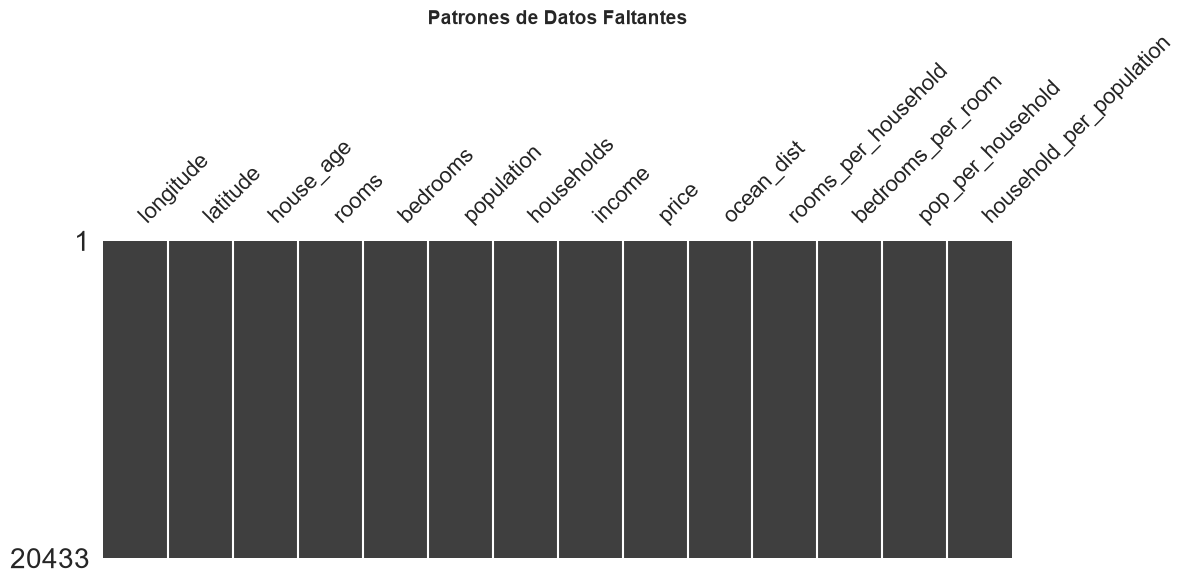


RESUMEN DE DATOS FALTANTES
                          null_count  %_missing  fake_nulls fake_values_found  total_missing  %_total
longitude                          0        0.0           0                []              0      0.0
latitude                           0        0.0           0                []              0      0.0
house_age                          0        0.0           0                []              0      0.0
rooms                              0        0.0           0                []              0      0.0
bedrooms                           0        0.0           0                []              0      0.0
population                         0        0.0           0                []              0      0.0
households                         0        0.0           0                []              0      0.0
income                             0        0.0           0                []              0      0.0
price                              0        0.0       

In [11]:
null_audit(df)

In [12]:
null_smart_dendrogram(df)

No se puede crear el dendrograma. Columnas con nulos: 0


In [13]:
null_smart_heatmap(df)

No se puede crear el mapa de calor. Columnas con nulos: 0


In [14]:
get_missing_raw_report(df, threshold=0.30)

No se encontraron filas que superen el umbral de valores faltantes.


### Duplicados

In [15]:
check_duplicates(df, subset = None)


ANÁLISIS DE DUPLICADOS
Filas con None duplicado: 0 (0.00%)
✓ No se encontraron duplicados


### Valores atípicos (Outliers)


Generando matriz de Outliers (Boxplots)...


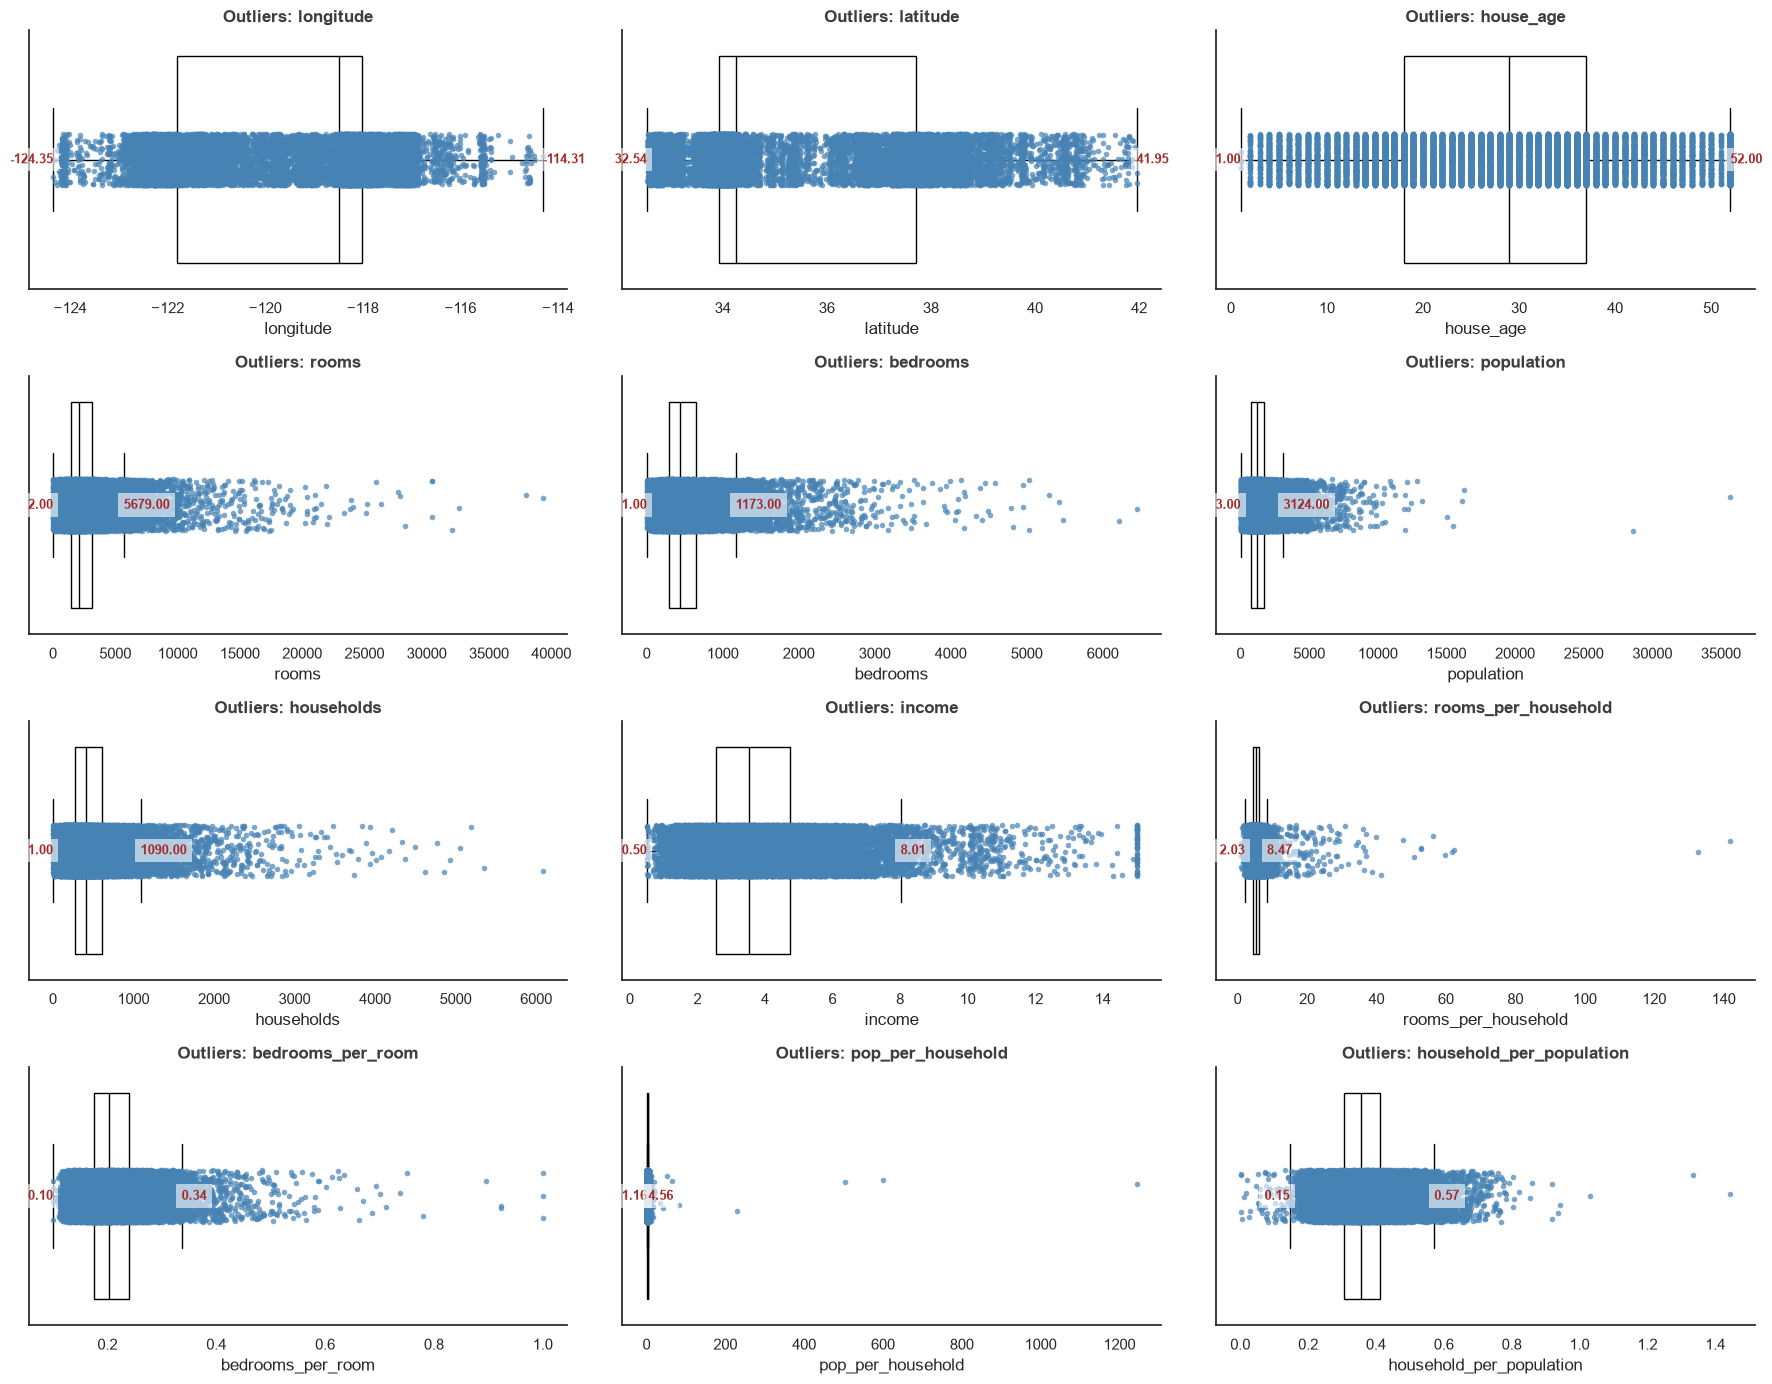

In [16]:
plot_regression_outliers(df, target)

## EDA (Análisis exploratorio de datos)

### Variable objetivo

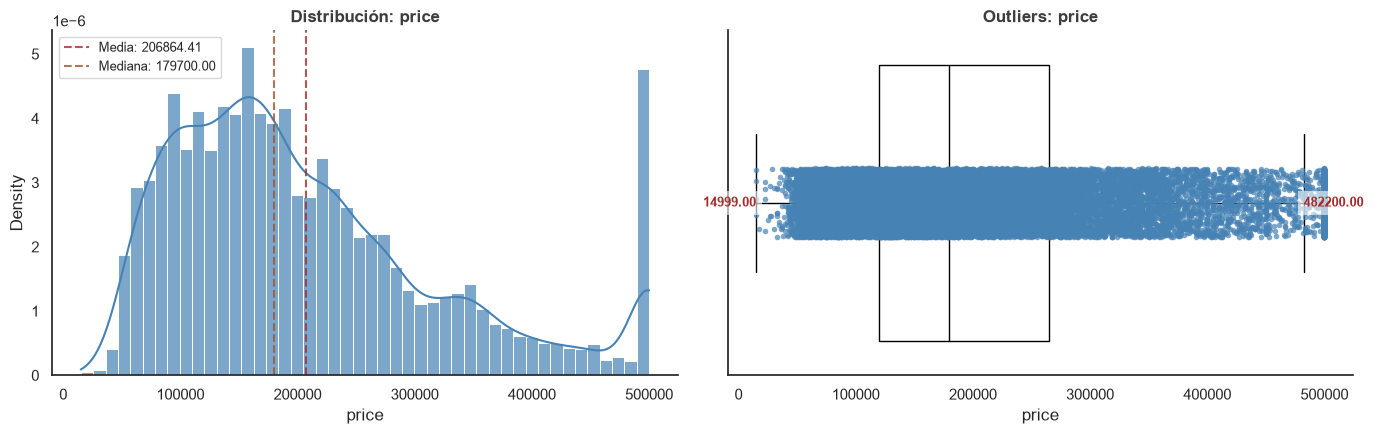

In [17]:
plot_target_reg(df, target)

In [18]:
## Anomalos
df.nlargest(5, 'price')

,longitude,latitude,house_age,rooms,bedrooms,population,households,income,price,ocean_dist,rooms_per_household,bedrooms_per_room,pop_per_household,household_per_population
89,-122.27,37.80,52.0,249.0,78.0,396.0,85.0,1.2434,500001.0,near bay,2.929412,0.313253,4.658824,0.214646
103,-118.47,33.99,24.0,1438.0,454.0,665.0,416.0,2.9750,500001.0,<1h ocean,3.456731,0.315716,1.598558,0.625564
105,-118.50,33.97,29.0,2737.0,808.0,1157.0,696.0,5.1280,500001.0,<1h ocean,3.932471,0.295214,1.662356,0.601556
107,-118.39,34.08,27.0,6605.0,1710.0,2665.0,1520.0,3.8088,500001.0,<1h ocean,4.345395,0.258895,1.753289,0.570356
132,-122.34,37.55,44.0,2465.0,328.0,843.0,324.0,6.9533,500001.0,near ocean,7.608025,0.133063,2.601852,0.384342


Evolución de la serie temporal del objetivo:<br>
No data available

### Análisis univariado

#### Distribuciones (Variables numéricas)

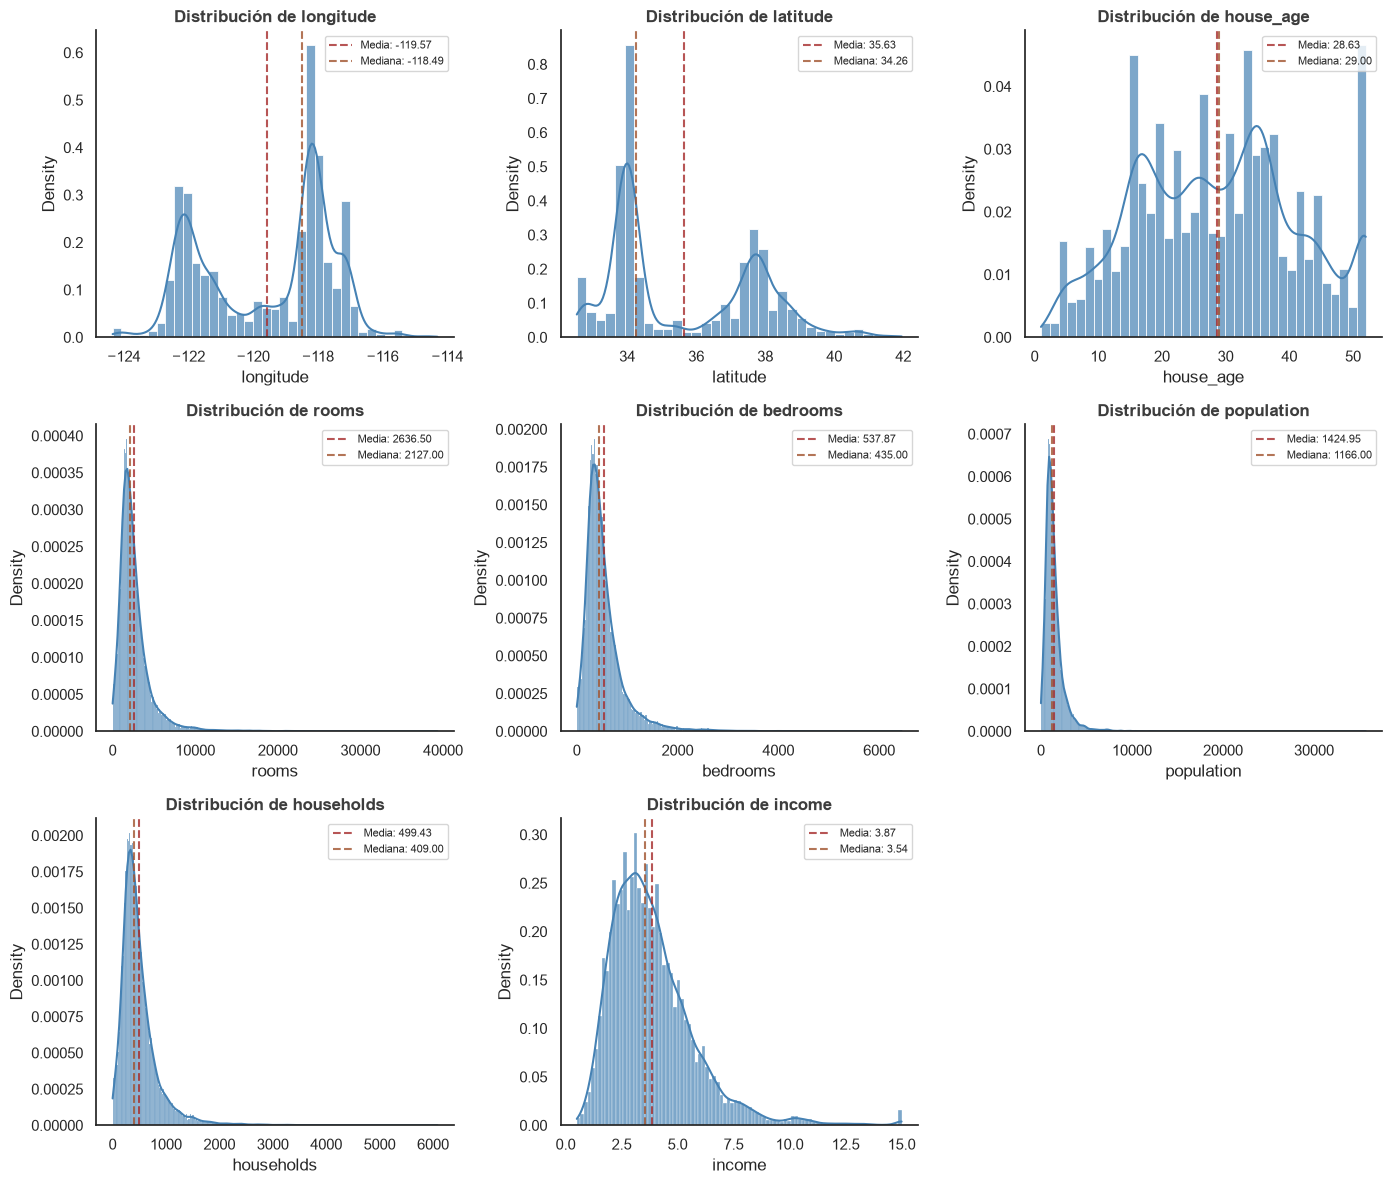


╔════════════════════════════════════════════════════════════════════════════╗
║                   LISTA DE VERIFICACIÓN DE DISTRIBUCIÓN                    ║
╠════════════════════════════════════════════════════════════════════════════╣
║ Distribución          → Campana            → OK para modelos lineales      ║
║ Asimetría (Skewness)  → Colas largas       → Aplicar log1p o boxcox        ║
║ Outliers              → Extremos en colas  → Eliminar (errores) o transf.  ║
║ Densidad              → Zonas dispersas    → Confirmar con outliers        ║
║ Escala                → Rangos distintos   → Estandarizar (StandardScaler) ║
║ Límites/Censura       → Barras verticales  → Eliminar (pocos) o categorizar║
║ Multimodal            → Múltiples picos    → Revisar clústeres geográficos ║
║ Naturaleza            → Continua a categ.  → Considerar trat. categórico   ║
╚════════════════════════════════════════════════════════════════════════════╝
    


In [19]:
plot_all_numeric_distributions_reg(df_num, target)

#### Frecuencias de variables binarias
Ninguna

#### Frecuencias de variables categóricas

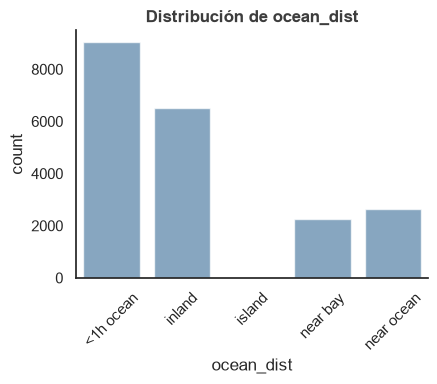

In [20]:
plot_categorical_counts_reg(df_cat, target, max_cat=10)

### Análisis bivariado

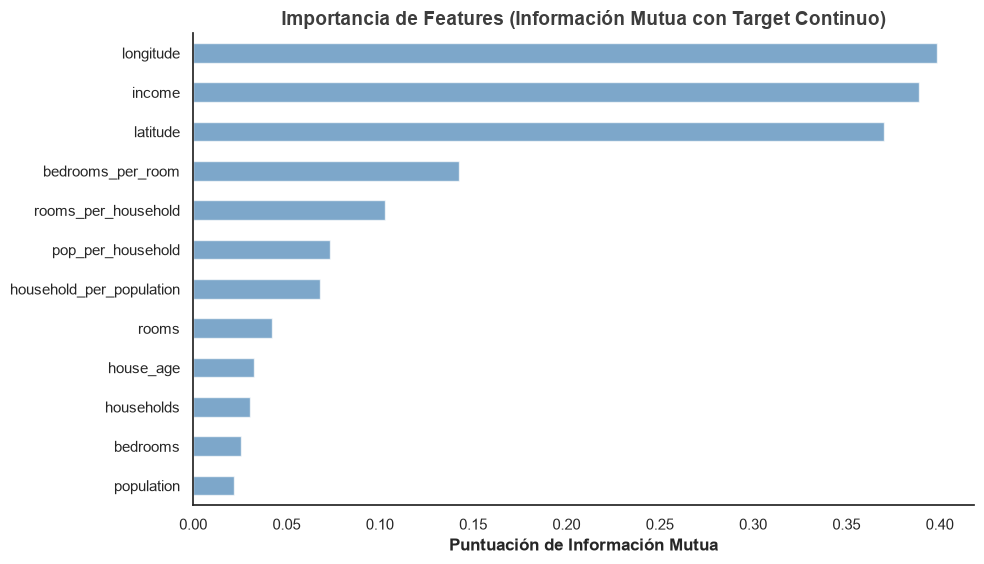

In [21]:
plot_feature_importance_min_reg(df, target)

#### Variables numéricas vs Variable objetivo

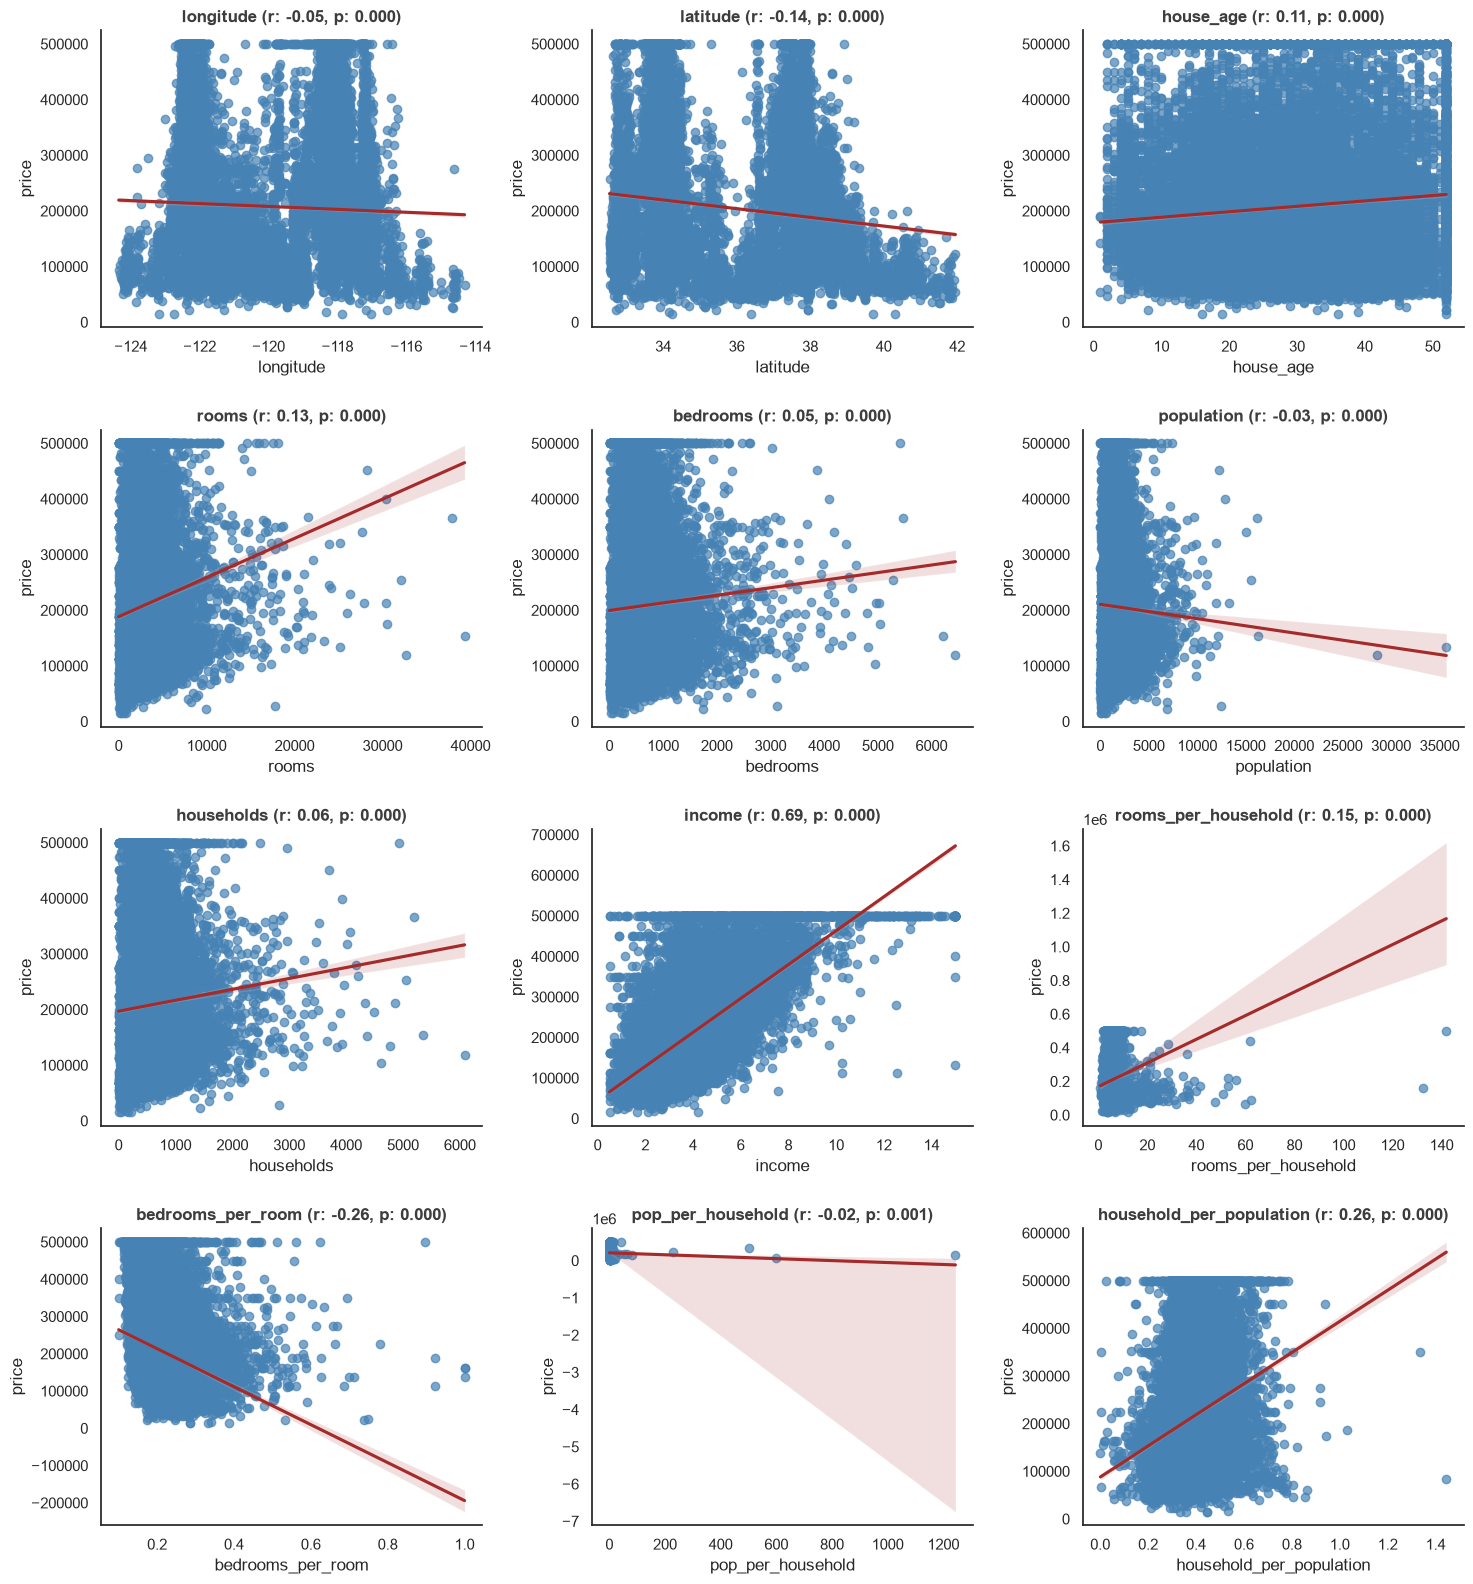

In [22]:
plot_relational_grid_reg(df, target)

#### Variables binarias vs Variable objetivo
Ninguna

#### Variables categóricas vs Variable objetivo

In [23]:
get_categorical_to_numeric_report(df, target)

,Feature,Max_Concentration,P_Value_Kruskal,Is_Significant,MI_Score,Verdict
0,ocean_dist,44.21%,0.0,YES,0.20884,KEEP



Generando matriz Categórica vs Continua...


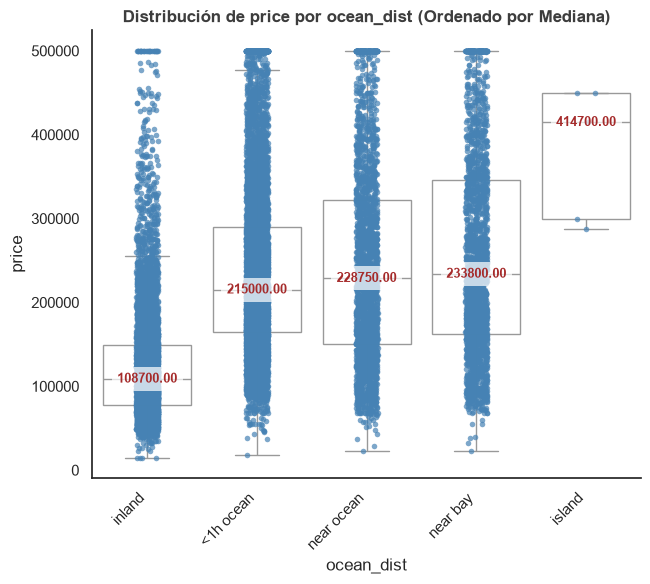

In [24]:
plot_categorical_vs_target_reg(df, target)

#### Variables Categóricas vs Variable Categóricas (opcional)
Ninguno

### Análisis Multivariado

#### Variables Numéricas

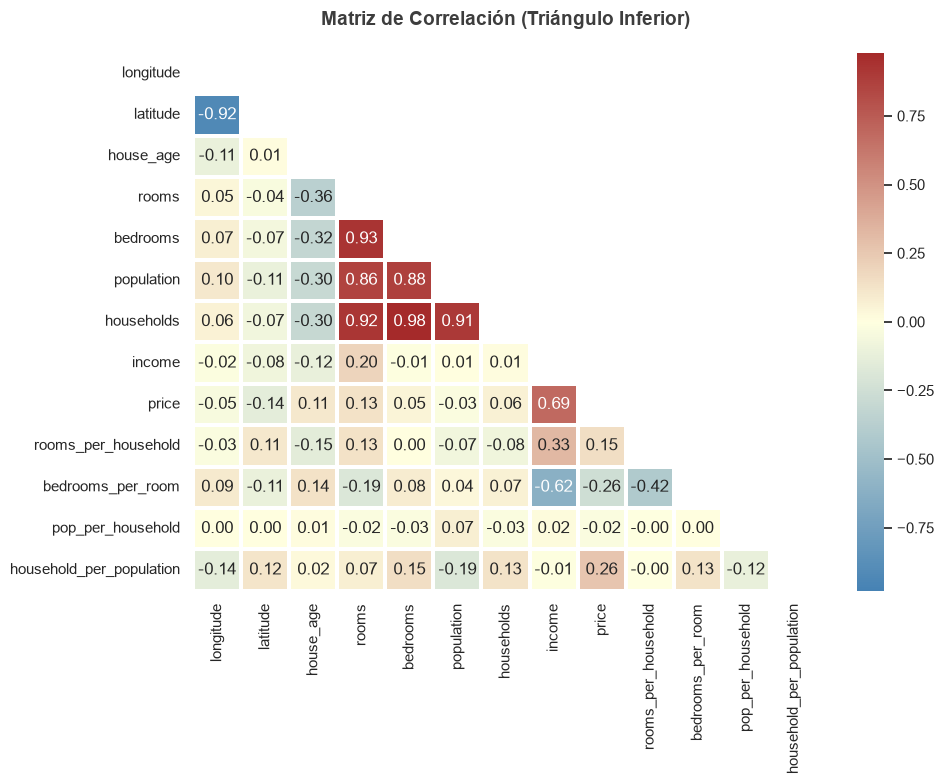

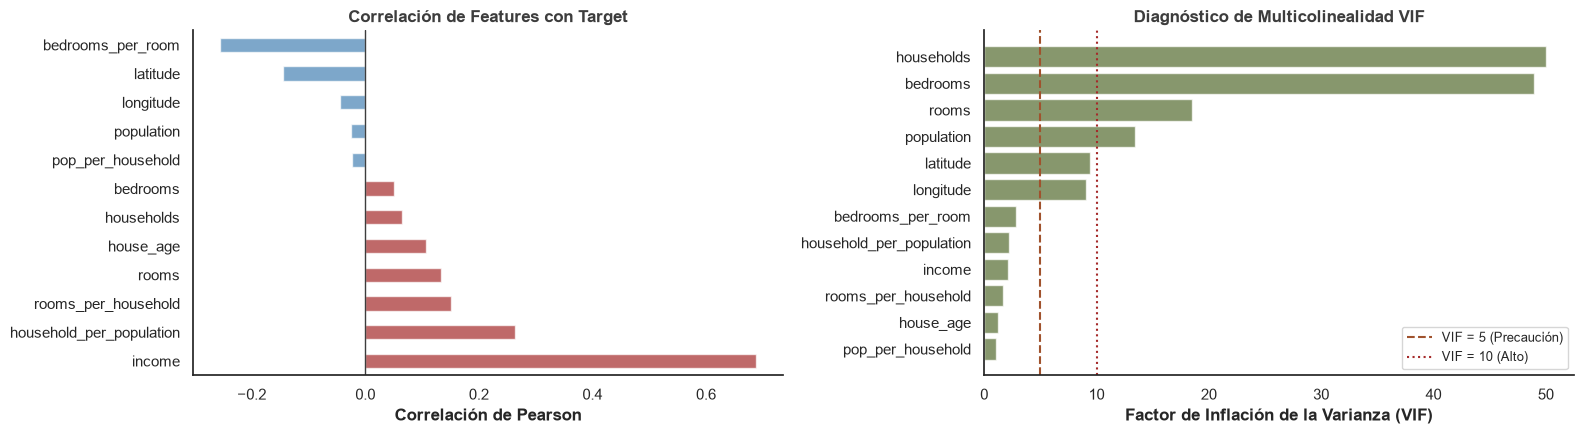


╔════════════════════════════════════════════════════════════════════════════╗
║                     GUÍA DE RESOLUCIÓN DE VIF                              ║
╠════════════════════════════════════════════════════════════════════════════╣
║ Regla práctica: VIF < 5 (Bueno) | VIF 5-10 (Precaución) | VIF > 10 (Elim.) ║
║ NO ELIMINAR si es importante por teoría, si se usan árboles o si           ║
║ se usa Ridge/Lasso (manejan VIF automáticamente). Árboles son inmunes a VIF║
╚════════════════════════════════════════════════════════════════════════════╝
    


In [25]:
plot_numeric_correlation_reg(df, target)

#### Ingeniería de Características Simple
Después de crear, verificar que no haya más multicolinealidad 

In [26]:
df['rooms_per_household'] = df['rooms'] / df['households']
df['bedrooms_per_room'] = df['bedrooms'] / df['rooms']
df['pop_per_household'] = df['population'] / df['households']
df['household_per_population'] = df['households'] / df['population']

#### Mapa geográfico

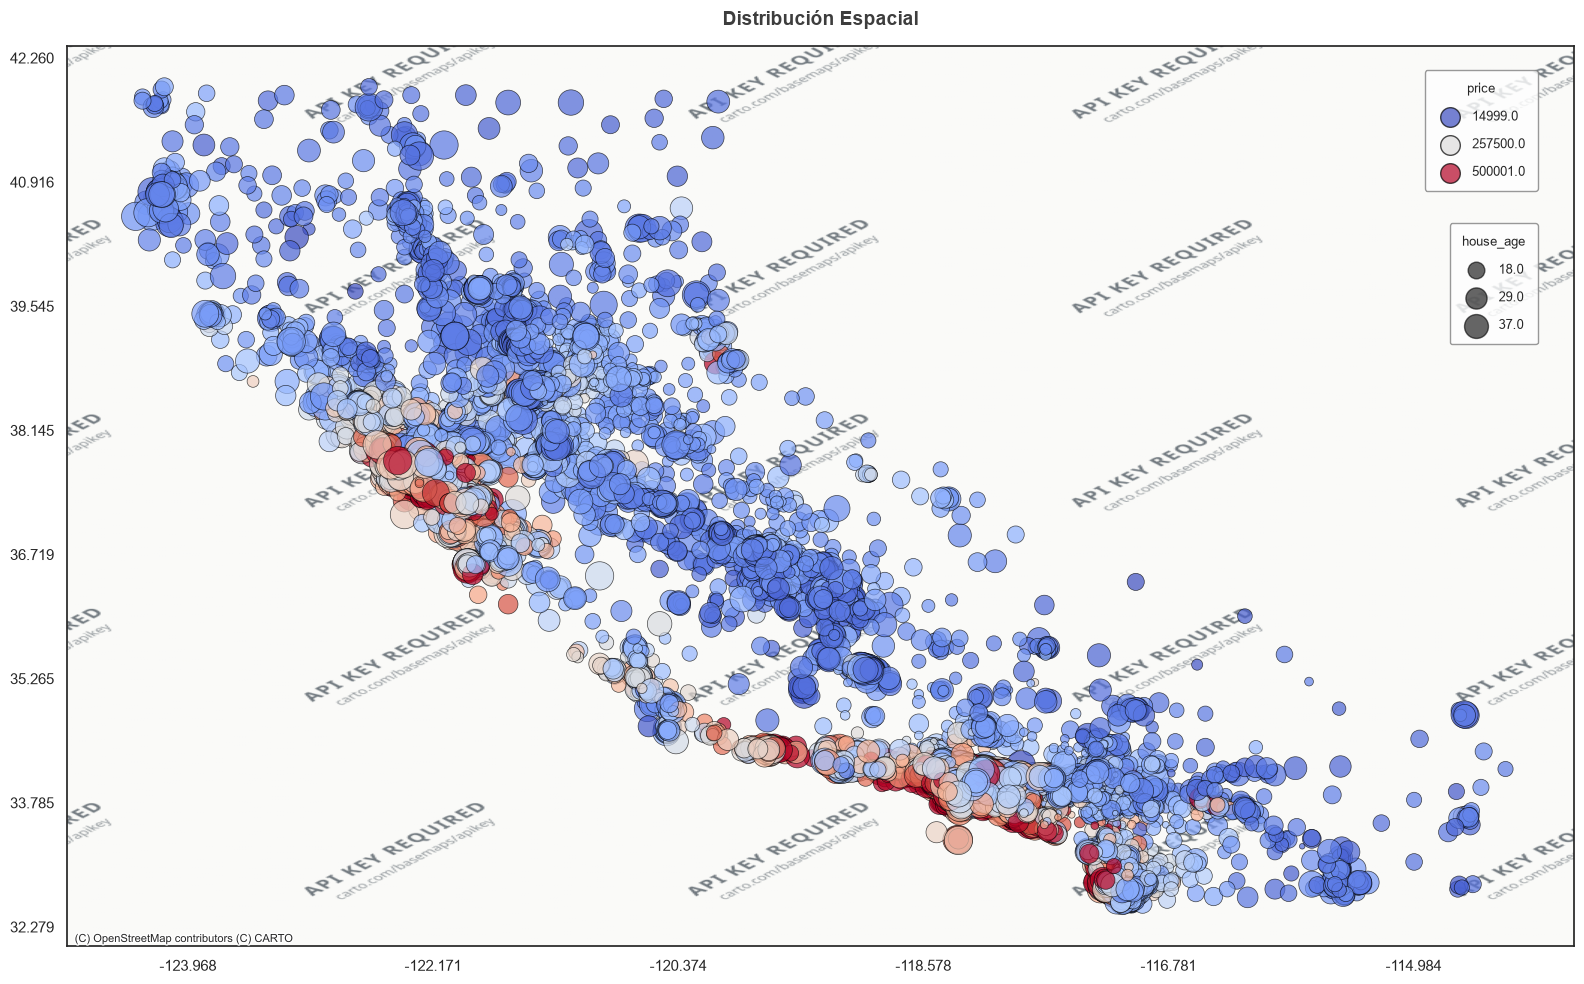

In [27]:
plot_geo_distribution(df, "longitude", "latitude", "price", "house_age")

### Variables categóricas
Ninguna

### Alta dimensionalidad

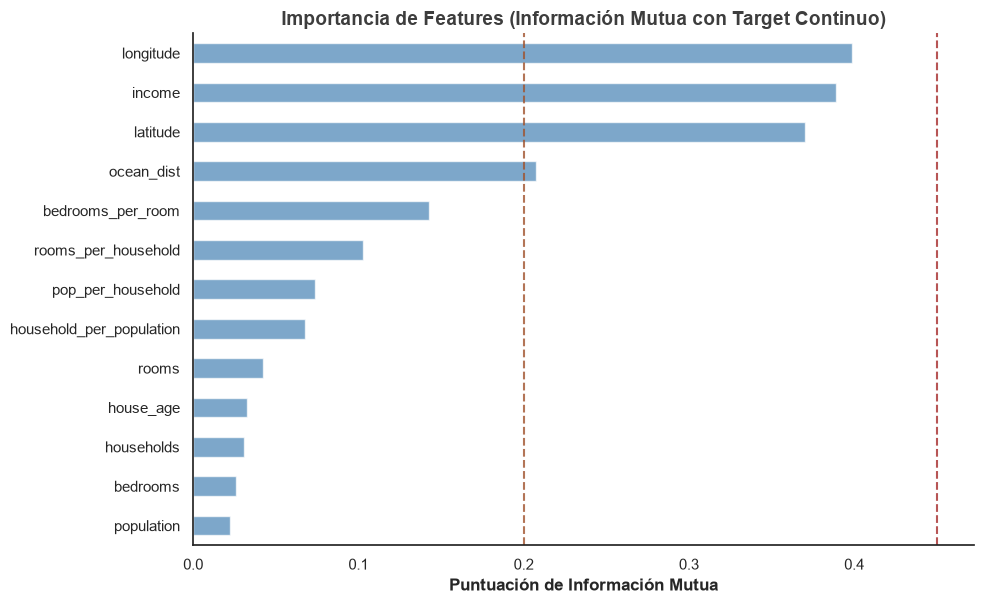

In [28]:
plot_feature_importance_max_reg(df, target)

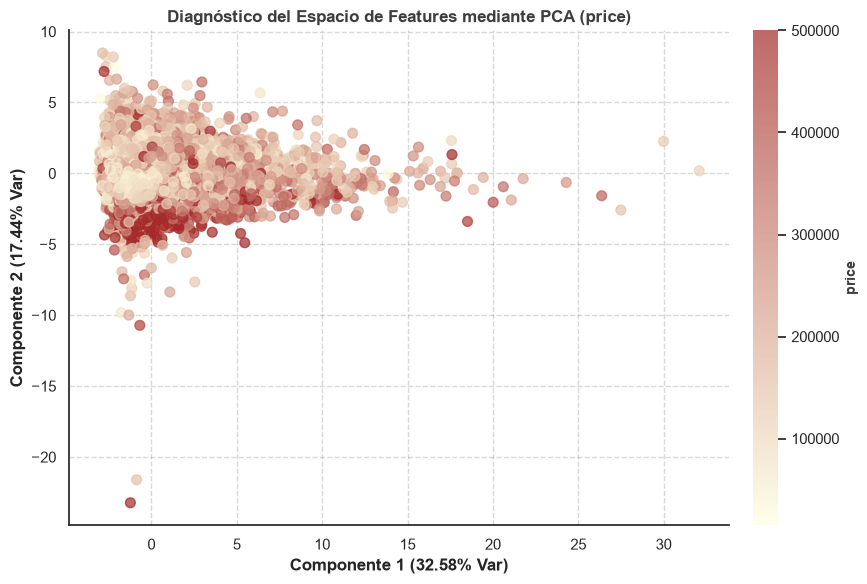

In [29]:
diagnostic_pca_dimensions_reg(df, target)

## Dataset final

In [30]:
df.head(3)

,longitude,latitude,house_age,rooms,bedrooms,population,households,income,price,ocean_dist,rooms_per_household,bedrooms_per_room,pop_per_household,household_per_population
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,near bay,6.984127,0.146591,2.555556,0.391304
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,near bay,6.238137,0.155797,2.109842,0.473969
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,near bay,8.288136,0.129516,2.802260,0.356855


Selección de columnas 

In [31]:
df = df[[ 'house_age', 'households', 'income',
          'population',
          #'household_per_population',
          'latitude', 'longitude',
          # 'rooms_per_household', 'bedrooms_per_room', 'pop_per_household',
          'rooms', 'bedrooms',
          'ocean_dist',
          'price']]

## Descarga

In [32]:
df.to_csv("housing_EDA.csv", index=False)